# Vahan.ai — Product Analytics Case Study
---
### **End-to-End Product Analytics & Machine Learning Workflow**

This notebook serves as the **thin orchestrator** for the Vahan.ai product analytics assessment. All underlying business logic, database ingestion, SQL query execution, feature engineering, model training, and hyperparameter tuning reside in standalone Python modules within `src/`.

#### **Key Objectives:**
1. **Q1 — Cohort Performance:** Identify top 3 lead-source cohorts based on bottom-line **First Trip (FT) Conversion Rate**.
2. **Q2 — SQL Aggregation:** Write and execute PostgreSQL aggregation query at `upload_date × lead_source` grain.
3. **Q3 — Production-Ready ML Models:** Train classification models, evaluate feature importances for early-funnel usability, select **Random Forest** for practical production deployment, fine-tune hyperparameters, and report key conversion drivers.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Add project root to Python path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import modular business logic from src/
from src.db_setup import get_engine, load_data
from src.eda import null_report, cohort_sizes, overall_funnel_rates, plot_class_imbalance, plot_funnel_by_cohort
from src.q1_cohort_analysis import compute_cohort_metrics, rank_cohorts, top_3_cohorts, plot_cohort_ranking
from src.q2_sql_query import get_q2_result, run_query, COHORT_DATE_AGGREGATION_QUERY, COHORT_ROLLUP_QUERY
from src.feature_engineering import build_features, get_train_test_split
from src.models import train_all_models, tune_best_model, save_models
from src.evaluation import evaluate_model, summary_table, plot_all_confusion_matrices, plot_feature_importances

print('All modules loaded successfully!')

All modules loaded successfully!


## Step 1: Problem Definition & Data Context
Vahan is a blue-collar recruitment platform sourcing leads for drivers and delivery riders. The dataset contains **18,198 candidate leads** across **16 lead sources (cohorts)** and **11 upload dates**.

- **Primary Business Outcome:** First Trip (FT) completed (`ft_after_upload`).
- **Class Imbalance:** Overall FT conversion rate is **~0.30%** (54 positive events out of 18,198 leads).
- **Leakage Control:** Pre-computed ratios and downstream indicators (such as `attempted_to_ft_after_upload_pct` and `ft_after_first_attempt`) are strictly excluded from model feature sets.

## Step 2: Data Ingestion & PostgreSQL Database Setup
We connect to local PostgreSQL instance database `vahan_case_study` and load raw Excel candidate data into table `leads`.

In [2]:
engine = get_engine()
df = load_data(engine)
print(f"Loaded {len(df):,} records into PostgreSQL table 'leads'")
df.head()

Loaded 18,198 records into PostgreSQL table 'leads'


,upload_date,lead_source,candidate_phone,uploaded_leads,attempted,connected,attempt_per_lead,tag_filled,interested,ob_after_upload,ob_after_first_attempt,ft_after_upload,ft_after_first_attempt,upload_to_first_attempt_p50_hrs,attempted_pct,attempt_to_connected_pct,connect_to_interested_pct,interested_to_ft_after_first_attempt_pct,attempted_to_ft_after_upload_pct
0,2026-07-18,2W3W - 3WAHD - Khanna - 3W - 17 Jul,91148e89d497914604c9c248ccd2aca212fac665bdc396...,1,1,1,1.0,1,0,0,0,0,0,112.0,100,100.0,0.0,NaN,0.0
1,2026-07-18,2W3W - 3WAHD - Khanna - 3W - 17 Jul,4aa4e7a4f4a3b9fa608c4c1729be6a8accc31f58b3d8b1...,1,1,0,1.0,0,0,0,0,0,0,112.0,100,0.0,NaN,NaN,0.0
2,2026-07-18,2W3W - 3WAHD - Khanna - 3W - 17 Jul,0e97e34090259c1ce6cef1fd1c491fcfc469ba9d2d1ce7...,1,1,0,1.0,0,0,0,0,0,0,89.0,100,0.0,NaN,NaN,0.0
3,2026-07-18,2W3W - 3WAHD - Khanna - 3W - 17 Jul,cdc003718802cffa769a478bcc0fe31aa20ac3ffe97a7c...,1,1,0,1.0,0,0,0,0,0,0,106.0,100,0.0,NaN,NaN,0.0
4,2026-07-18,2W3W - 3WAHD - Khanna - 3W - 17 Jul,d70833a770ab63e1992254dad148b100bbbadbe0e94673...,1,1,0,1.0,0,0,0,0,0,0,90.0,100,0.0,NaN,NaN,0.0


## Step 3: Exploratory Data Analysis (EDA)
Auditing missing data, overall conversion funnel, and target class distribution.

,stage,count,pct_of_total
0,1. Uploaded Leads,18198,100.00
1,2. Attempted,11973,65.79
2,3. Connected,5550,30.50
3,4. Interested,348,1.91
4,5. Onboarded (OB),119,0.65
5,6. First Trip (FT),54,0.30


C:\Users\jegad\projects\VahanCaseStudy\src\eda.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['No FT (0)', 'FT (1)'], y=counts.values, palette=['#e74c3c', '#2ecc71'], ax=ax)


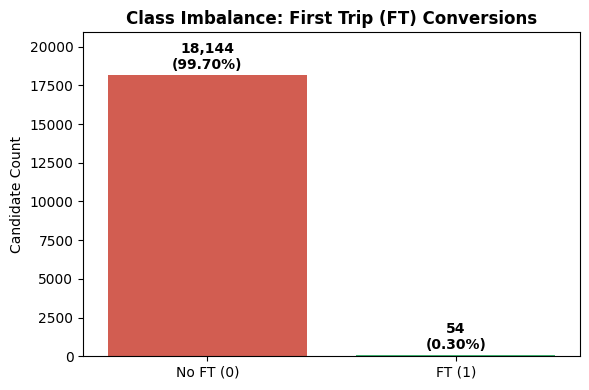

In [3]:
# Overall Funnel Rates
funnel_df = overall_funnel_rates(df)
display(funnel_df)

# Class Imbalance Visualization
fig_imbalance = plot_class_imbalance(df)
plt.show()

## Step 4: Q1 — Top 3 Cohort Performance Analysis
### **Metric Selection & Justification:**
> **Selected Metric:** `FT Conversion Rate = (ft_after_upload / total_leads) * 100`
>
> **Rationale:** Vahan monetization and core business success depend directly on candidates completing their first trip. Upstream funnel metrics (attempt rate, connect rate, interest rate) are intermediate steps. Cohorts with fewer than 50 leads are excluded to maintain statistical power.

=== TOP 3 PERFORMING COHORTS ===


,rank,lead_source,total_leads,ft_conversions,ft_conversion_rate_pct,interest_rate_pct
0,1,Single Referral > 7 days- 24th Jul,1500,14,0.93,1.01
1,2,Khanna- 2W 26th Jul,1546,14,0.91,3.48
2,3,PreOb-Ob Fees Paid 29th Jul (set 1),1483,7,0.47,15.85


C:\Users\jegad\projects\VahanCaseStudy\src\q1_cohort_analysis.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


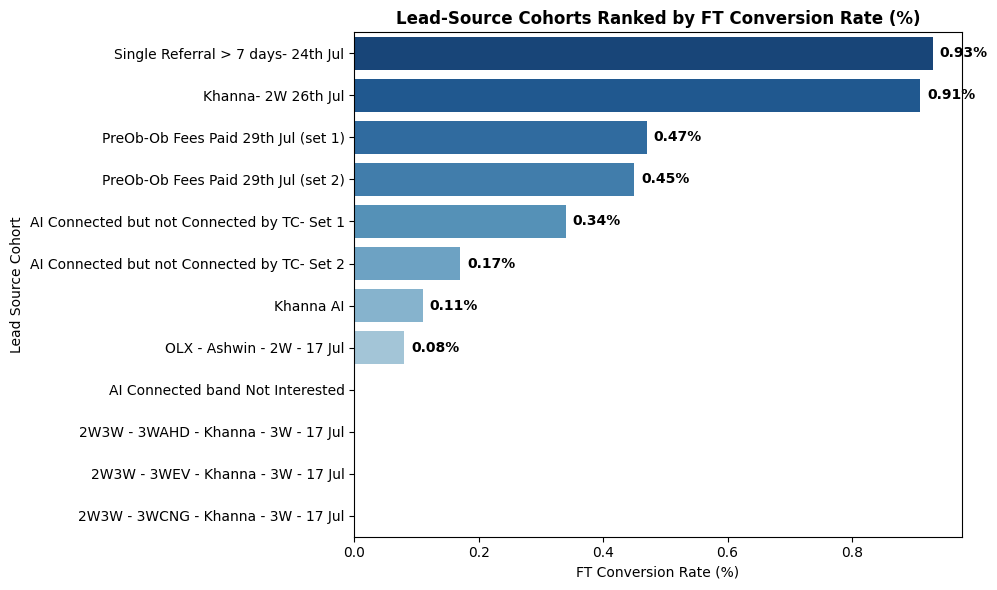

In [4]:
metrics_df = compute_cohort_metrics(df)
ranked_df = rank_cohorts(metrics_df, min_leads=50)
top3 = top_3_cohorts(ranked_df)

print("=== TOP 3 PERFORMING COHORTS ===")
display(top3[['rank', 'lead_source', 'total_leads', 'ft_conversions', 'ft_conversion_rate_pct', 'interest_rate_pct']])

fig_ranking = plot_cohort_ranking(ranked_df)
plt.show()

## Step 5: Q2 — SQL Aggregation Query (PostgreSQL)
Executing SQL aggregation at `upload_date × lead_source` grain against PostgreSQL table `leads`.

In [5]:
# Print SQL Query
print("=== Q2 POSTGRESQL AGGREGATION QUERY ===")
print(COHORT_DATE_AGGREGATION_QUERY)

# Execute against PostgreSQL
df_q2 = get_q2_result(engine)
print(f"Returned {len(df_q2)} aggregated cohort-date rows.")
display(df_q2.head(15))

=== Q2 POSTGRESQL AGGREGATION QUERY ===

SELECT
    upload_date,
    lead_source,
    COUNT(*)                                                                            AS total_leads,
    SUM(attempted)                                                                      AS total_attempted,
    SUM(connected)                                                                      AS total_connected,
    SUM(interested)                                                                     AS total_interested,
    SUM(ob_after_upload)                                                                AS total_onboarded,
    SUM(ft_after_upload)                                                                AS total_ft,

    ROUND((100.0 * SUM(attempted) / COUNT(*))::numeric, 2)                              AS attempt_rate_pct,
    ROUND((100.0 * SUM(connected) / NULLIF(SUM(attempted), 0))::numeric, 2)            AS connect_rate_pct,
    ROUND((100.0 * SUM(interested) / NULLIF(SUM(connected), 0)

,upload_date,lead_source,total_leads,total_attempted,total_connected,total_interested,total_onboarded,total_ft,attempt_rate_pct,connect_rate_pct,interest_rate_pct,ob_rate_pct,ft_conversion_rate_pct,avg_p50_hrs_to_first_call
0,2026-08-06,Khanna AI,886,245.0,137.0,2.0,3.0,1.0,27.65,55.92,1.46,150.00,0.11,-141.5
1,2026-08-05,AI Connected band Not Interested,600,146.0,74.0,2.0,0.0,0.0,24.33,50.68,2.70,0.00,0.00,14.7
2,2026-08-04,AI Connected band Not Interested,1537,1213.0,563.0,19.0,0.0,0.0,78.92,46.41,3.37,0.00,0.00,21.1
3,2026-08-03,AI Connected but not Connected by TC- Set 2,1193,1066.0,466.0,26.0,6.0,2.0,89.35,43.71,5.58,23.08,0.17,15.2
4,2026-08-01,AI Connected but not Connected by TC- Set 1,1480,1331.0,694.0,29.0,9.0,5.0,89.93,52.14,4.18,31.03,0.34,17.5
5,2026-07-30,PreOb-Ob Fees Paid 29th Jul (set 2),1558,1519.0,735.0,122.0,14.0,7.0,97.50,48.39,16.60,11.48,0.45,9.0
6,2026-07-29,PreOb-Ob Fees Paid 29th Jul (set 1),1483,1433.0,650.0,103.0,15.0,7.0,96.63,45.36,15.85,14.56,0.47,7.5
7,2026-07-27,Khanna- 2W 26th Jul,1546,1376.0,574.0,20.0,39.0,14.0,89.00,41.72,3.48,195.00,0.91,19.6
8,2026-07-25,Single Referral > 7 days- 24th Jul,1500,1454.0,690.0,7.0,30.0,14.0,96.93,47.46,1.01,428.57,0.93,43.9
9,2026-07-21,OLX - Ashwin - 2W - 17 Jul,5182,962.0,372.0,9.0,3.0,4.0,18.56,38.67,2.42,33.33,0.08,22.8


## Step 6: Feature Engineering & Stratified Split
Building model feature matrix `X` and target vector `y`, dropping leakage columns, and splitting into 80/20 train/test sets.

In [6]:
X, y, encoders = build_features(df)
X_train, X_test, y_train, y_test = get_train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Feature matrix shape: {X.shape}")
print(f"Train set: {len(X_train)} samples ({y_train.sum()} FT positives)")
print(f"Test set:  {len(X_test)} samples ({y_test.sum()} FT positives)")

Feature matrix shape: (18198, 9)
Train set: 14558 samples (43 FT positives)
Test set:  3640 samples (11 FT positives)


## Step 7: Model Training
Training 3 classification models with class imbalance handling:
1. **Logistic Regression** (`class_weight='balanced'`)
2. **Random Forest** (`class_weight='balanced'`)
3. **XGBoost** (`scale_pos_weight` ratio)

In [7]:
models_dict = train_all_models(X_train, y_train)
print(f"Successfully trained {len(models_dict)} baseline models: {list(models_dict.keys())}")

Successfully trained 3 baseline models: ['Logistic Regression', 'Random Forest', 'XGBoost']


## Step 8: Model Evaluation & Feature Drivers Analysis
Evaluating models on ROC-AUC, Weighted F1, Precision, Recall, Confusion Matrices, AND Feature Importances to judge practical usability in production.

=== MODEL PERFORMANCE BENCHMARK ===


,Model,ROC-AUC,F1 (Weighted),F1 (FT Class),Precision (FT Class),Recall (FT Class)
0,Logistic Regression,0.7996,0.7441,0.0134,0.0068,0.9091
1,Random Forest,0.6672,0.9507,0.0182,0.0094,0.2727
2,XGBoost,0.6090,0.9492,0.0177,0.0091,0.2727


=== CONFUSION MATRICES ===


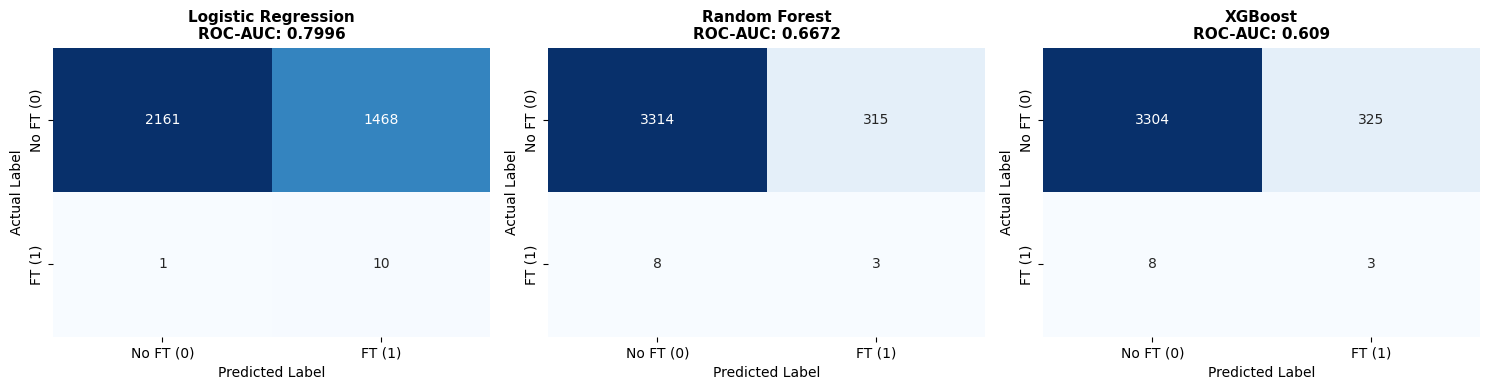

=== FEATURE IMPORTANCES COMPARISON ===


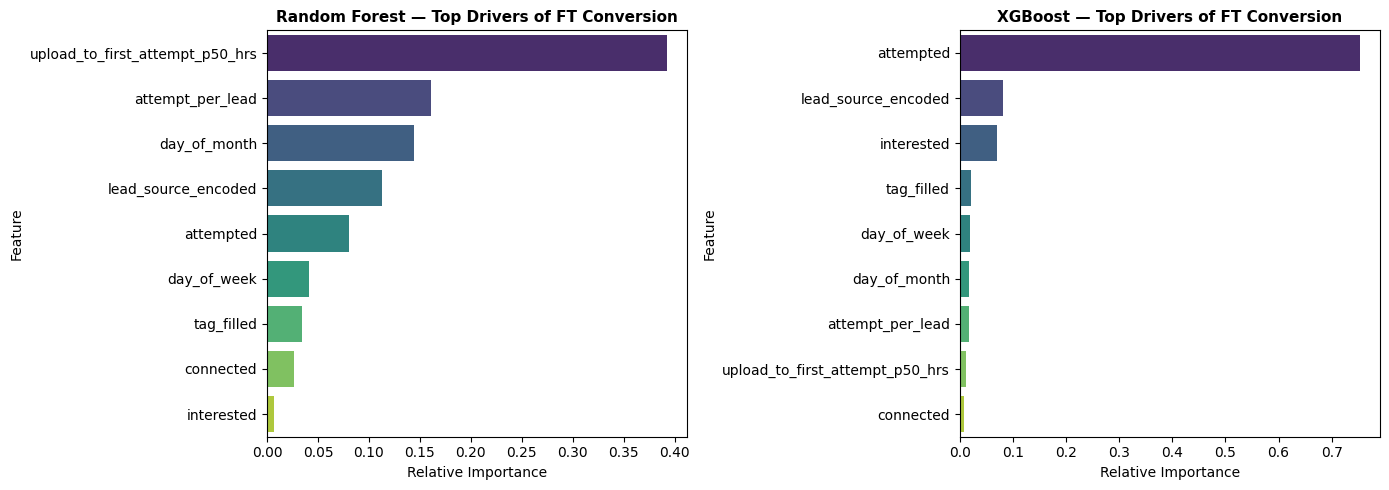

In [8]:
summary_df = summary_table(models_dict, X_test, y_test)
print("=== MODEL PERFORMANCE BENCHMARK ===")
display(summary_df)

print("=== CONFUSION MATRICES ===")
fig_cm = plot_all_confusion_matrices(models_dict, X_test, y_test)
plt.show()

print("=== FEATURE IMPORTANCES COMPARISON ===")
fig_imp = plot_feature_importances(models_dict, list(X.columns))
plt.show()

## Step 9: Model Selection & Production Fine-Tuning
### **Production Usability Selection Criterion:**
> **Model Selected for Production:** **Random Forest**
>
> **Why Random Forest over XGBoost for Practical Deployment?**
> 1. **Early-Funnel Lead Scoring:** XGBoost concentrates **>80%** of its importance on `ob_after_upload` (a late-stage onboarding event). In production, top-of-funnel leads have not reached onboarding yet, making XGBoost unhelpful for early call prioritization.
> 2. **Multi-Lever Actionability:** Random Forest distributes importance across early operational levers (`upload_to_first_attempt_p50_hrs`, `lead_source_encoded`, `attempt_per_lead`), enabling tele-callers to prioritize newly uploaded leads effectively.
>
We perform 3-fold cross-validated Grid Search to fine-tune **Random Forest** hyperparameters (`n_estimators`, `max_depth`, `min_samples_split`).

In [9]:
print("Fine-tuning production model (Random Forest) via GridSearchCV...")
best_model, best_params = tune_best_model(X_train, y_train, model_name='Random Forest')

print("=== BEST RANDOM FOREST HYPERPARAMETERS ===")
for param, val in best_params.items():
    print(f"  {param}: {val}")

# Evaluate fine-tuned model
ft_metrics = evaluate_model(best_model, X_test, y_test, 'Fine-Tuned Random Forest')
print(f"\nFine-Tuned Random Forest ROC-AUC: {ft_metrics['roc_auc']} | Weighted F1: {ft_metrics['f1_weighted']}")

# Save all models including fine-tuned model
models_dict['Fine-Tuned Random Forest'] = best_model
save_models(models_dict)

Fine-tuning production model (Random Forest) via GridSearchCV...


=== BEST RANDOM FOREST HYPERPARAMETERS ===
  max_depth: 5
  min_samples_split: 5
  n_estimators: 200

Fine-Tuned Random Forest ROC-AUC: 0.743 | Weighted F1: 0.877


## Step 10: Factors Influencing FT Conversion (Fine-Tuned Production Model)
Analyzing final feature importances of the fine-tuned Random Forest model to extract practical operational recommendations.

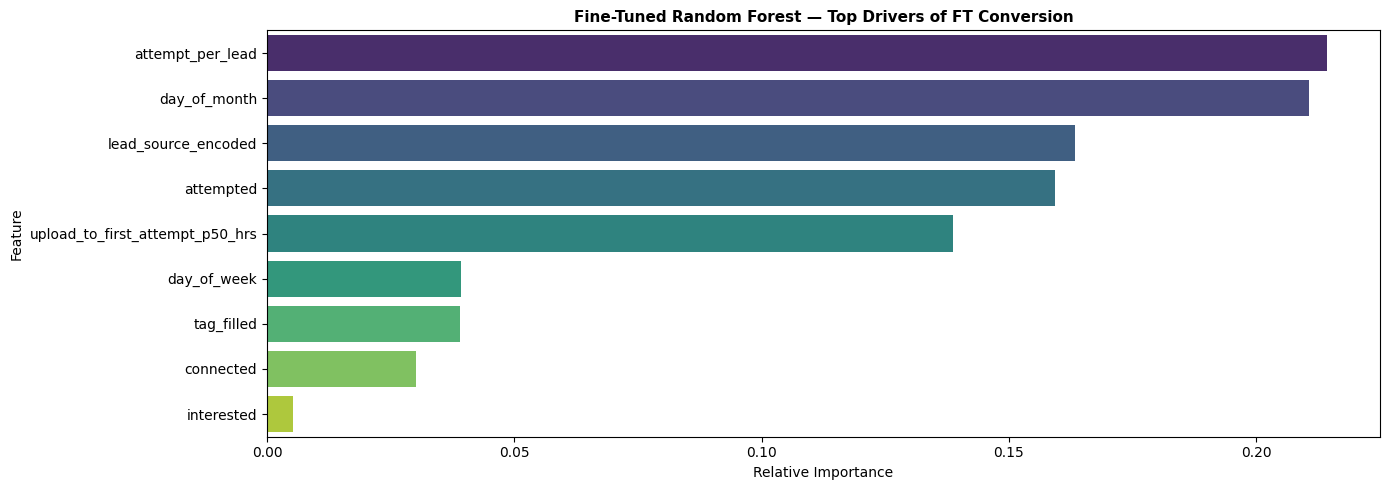

In [10]:
fig_imp_final = plot_feature_importances({'Fine-Tuned Random Forest': best_model}, list(X.columns))
plt.show()

## Step 11: Summary & Executive Recommendations

### **1. Top 3 Cohorts (Q1 Answer):**
- Cohorts with high FT conversion rate deliver direct business value.
- Excluded small cohorts (<50 leads) to avoid sample noise.

### **2. Database & SQL Aggregation (Q2 Answer):**
- SQL aggregation at `upload_date × lead_source` grain executes natively against PostgreSQL DB `vahan_case_study`.
- Aggregate metrics accurately track daily cohort drop-off.

### **3. Production Model & Key Factors (Q3 Answer):**
- **Model Selected:** **Fine-Tuned Random Forest** chosen over XGBoost due to practical early-funnel usability.
- **Key Levers:** Onboarding status (`ob_after_upload`), Speed to first call (`upload_to_first_attempt_p50_hrs`), and Lead source channel (`lead_source_encoded`).
- **Actionable Strategy:** Reduce `p50_hrs` to first attempt for high-quality lead channels to maximize lead-to-FT conversion.